In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import precision_score, recall_score, f1_score, silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neighbors import NearestNeighbors

In [24]:
rand = 42
sample_amount = 40_000
feature_amount = 20
blob_amount = 8
cluster_std = 1.2

X, _ = make_blobs(n_samples=sample_amount, n_features=feature_amount, centers=blob_amount, cluster_std=cluster_std, random_state=rand,)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [25]:
def inject_noise(df, noise_frac, seed, n_features_affected=None):
    rng = np.random.default_rng(seed)
    noisy = df.copy()
    cols_all = df.columns
    n = len(df)
    n_noise = int(n * noise_frac)
    noise_idx = rng.choice(df.index, size=n_noise, replace=False)
    mask = np.zeros(n, dtype=int)
    for row_id in noise_idx:
        method = rng.integers(low=1, high=5, endpoint=True)
        mask[row_id] = method
        match (method):
            case 1:
                cols = cols_all
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(8, 12) * std

            case 2:
                cols = rng.choice(cols_all, size=n_features_affected, replace=False)
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(2, 4) * std

            case 3:
                wide_n = min(int(n_features_affected * 2.0), int(len(cols_all) * 0.5))
                cols = rng.choice(cols_all, size=wide_n, replace=False)
                donor_row = rng.choice(df.index[df.index != row_id])
                for col in cols:
                    noisy.loc[row_id, col] = df.loc[donor_row, col]

            case 4:
                wide_n = max(3, n_features_affected - 1)
                cols = rng.choice(cols_all, size=wide_n, replace=False)
                for col in cols:
                    donor_row = rng.choice(df.index[df.index != row_id])
                    noisy.loc[row_id, col] = df.loc[donor_row, col]

            case 5:
                narrow_n = max(3, int(n_features_affected * 0.8))
                cols = rng.choice(cols_all, size=narrow_n, replace=False)
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(0.5, 0.85) * std

    return noisy, pd.Series(mask, index=df.index)

contam=0.1

noisy_df, true_mask = inject_noise(df, noise_frac=contam, n_features_affected=5, seed=rand)

In [ ]:
#AMOUNT OF NOISE
print(len(np.array(np.where(true_mask == True)).reshape(-1))/len(true_mask))

In [ ]:
rand = 42

gt_2015 = pd.read_csv("gt_2015.csv")
gt_2014 = pd.read_csv("gt_2014.csv")
gt_2013 = pd.read_csv("gt_2013.csv")
gt_2012 = pd.read_csv("gt_2012.csv")
gt_2011 = pd.read_csv("gt_2011.csv")
noisy_df = pd.concat([gt_2015, gt_2014, gt_2013, gt_2012, gt_2011])

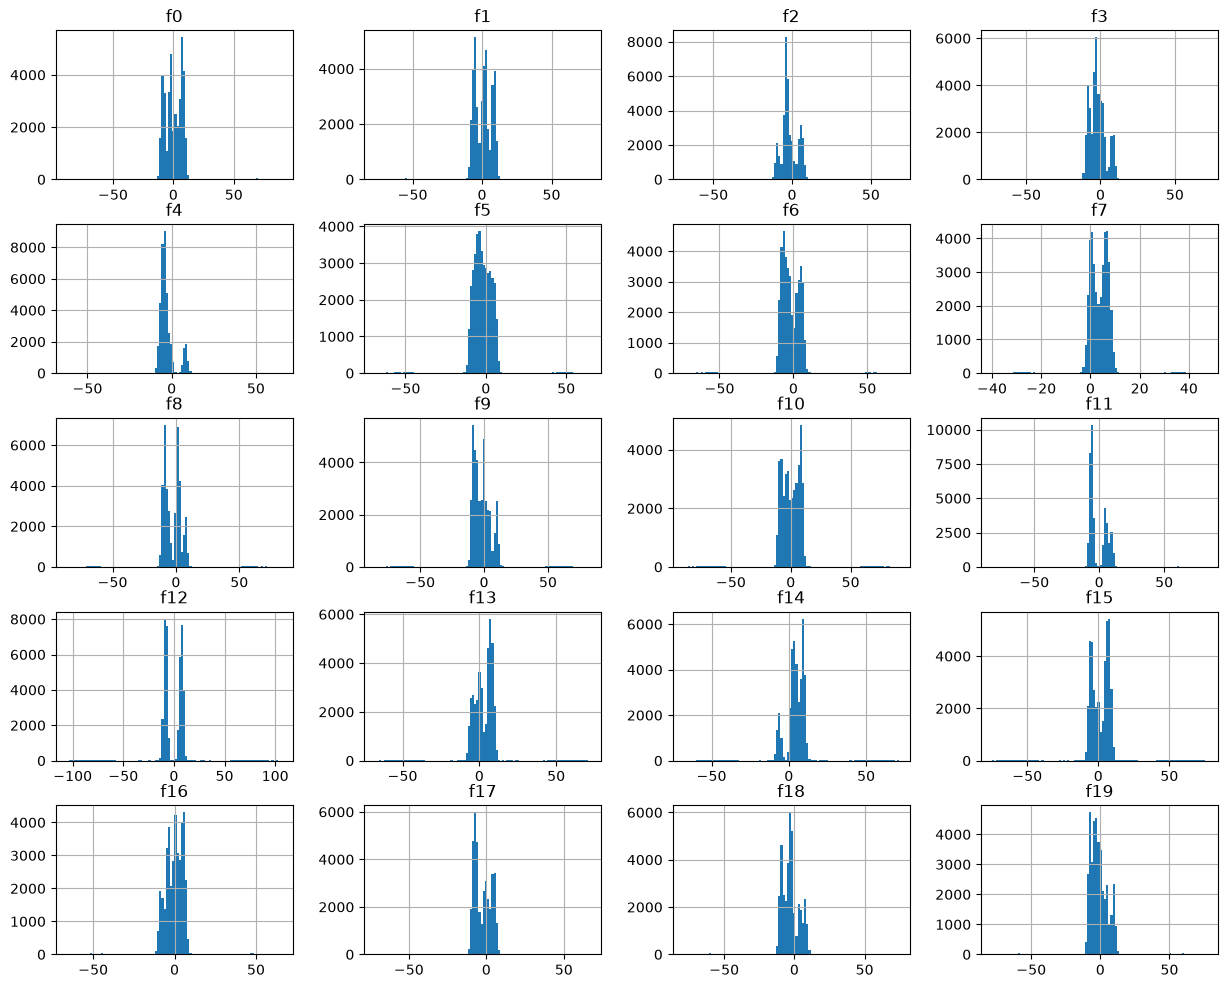

In [26]:
#HIST OF ALL FEATURES
noisy_df.hist(figsize=(15, 12), bins=100)
plt.show()

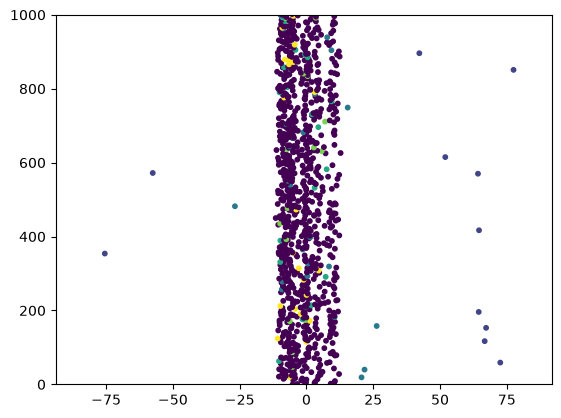

In [27]:
#PLOT FIRST FEATURE
try:
    plt.scatter(noisy_df.iloc[:, 9], noisy_df.index, s=10, c=true_mask)
    plt.ylim(0, 1_000)
    plt.show()
except:
    plt.scatter(noisy_df.iloc[:, 9], noisy_df.index, s=10)
    plt.ylim(0, 1_000)
    plt.show()

In [28]:
def impute_flagged_knn(data, flagged, knn_neighbors = 5):
    data = data.copy()
    clean = data.loc[~flagged]
    if flagged.sum() == 0 or len(clean) <= knn_neighbors:
        return data
    scaler = StandardScaler().fit(clean)
    nn = NearestNeighbors(n_neighbors=knn_neighbors).fit(scaler.transform(clean))
    _, idx = nn.kneighbors(scaler.transform(data.loc[flagged]))
    clean_vals = clean.to_numpy()
    imputed = clean_vals[idx].mean(axis=1)
    data.loc[flagged, :] = imputed
    return data

def metrics(flagged, mask=None):
    flagged = np.asarray(flagged)
    if mask is not None:
        n = [0, 0, 0, 0, 0, 0]
        m = [0, 0, 0, 0, 0, 0]
        for i in range(0, 6):
            m[i] = (mask == i).sum()
        for i in range(len(mask)):
            if flagged[i] == True:
                match mask.iloc[i]:
                    case 0:
                        n[0] += 1
                    case 1:
                        n[1] += 1
                    case 2:
                        n[2] += 1
                    case 3:
                        n[3] += 1
                    case 4:
                        n[4] += 1
                    case 5:
                        n[5] += 1
        # print(f"entry type:\tstart:\tflag:\tend:")
        # print(f"not noise:\t{m[0]}\t{n[0]}\t{m[0] - n[0]}")
        # for i in range(1, 6):
        #     print(f"noise {i}:\t{m[i]}\t{n[i]}\t{m[i] - n[i]}")
        tm = mask.squeeze().to_numpy()
        f = flagged.astype(int)
        results = []
        total_fp = ((tm == 0) & (f == 1)).sum()
        total_tn = ((tm == 0) & (f == 0)).sum()
        for i in range(1, 6):
            evaluate = (tm == i) | (tm == 0)
            tm_type = (tm[evaluate] == i).astype(int)
            f_type = f[evaluate]
            support = (tm_type == 1).sum()
            results.append({"noise type": f"noise {i}:", 
                            "TP": n[i],
                            "FN": m[i] - n[i],
                            "FP": "-",
                            "TN": "-",
                            "precision": precision_score(tm_type, f_type, zero_division=0), 
                            "recall": recall_score(tm_type, f_type, zero_division=0), 
                            "f1": f1_score(tm_type, f_type, zero_division=0),
                            "support": support})

        rdf = pd.DataFrame(results)
        total_row = {"noise type": f"total:", 
                            "TP": rdf["TP"].sum(),
                            "FN": rdf["FN"].sum(),
                            "FP": total_fp,
                            "TN": total_tn,
                            "precision": "-", 
                            "recall": "-", 
                            "f1": "-",
                            "support": rdf["support"].sum()}

        rdf = pd.concat([rdf, pd.DataFrame([total_row])], ignore_index=True)
        
        print(rdf)
    
def mitigate(data, flagged, mask=None, mitigation=1, knn_neighbors=5):
    flagged = np.asarray(flagged)
    match(mitigation):
        case 1: #remove
            keep = ~flagged
            data = data.loc[keep]
            if mask is not None:
                mask = mask[keep]

        case 2: #impute
            fixed_index = data.index[flagged]
            data = impute_flagged_knn(data, flagged, knn_neighbors=knn_neighbors)
            if mask is not None:
                mask = mask.copy()
                mask.loc[fixed_index] = 0

    print(f"\nflagged: {flagged.sum()} / {len(flagged)}")
    print(f"entries remaining: {len(data)}")
    print("=" * 45, "\n")

    if mask is not None:
        return data, mask
    return data

def run_iqr(data, iqr_fence, iqr_col_ratio, mask=None, mitigation=1, knn_neighbors=5):
    suspects = np.zeros(len(data), dtype=int)
    for col in data.columns:
        Q1 = np.percentile(data[col], 25)
        Q3 = np.percentile(data[col], 75)
        IQR = Q3 - Q1
        lower, upper = Q1 - iqr_fence * IQR, Q3 + iqr_fence * IQR
        suspects += (data[col] < lower) | (data[col] > upper)
    flagged = (suspects > len(data.columns) * iqr_col_ratio).to_numpy()
    metrics(flagged=flagged, mask=mask)
    return mitigate(data=data, flagged=flagged, mask=mask, mitigation=mitigation, knn_neighbors=knn_neighbors)

def run_isolation_forest(data, isof_estimators, mask=None, mitigation=2, knn_neighbors=5):
    model = IsolationForest(n_estimators=isof_estimators, contamination='auto', n_jobs=-1, random_state=rand)
    flagged = model.fit_predict(data) == -1
    metrics(flagged=flagged, mask=mask)
    return mitigate(data=data, flagged=flagged, mask=mask, mitigation=mitigation, knn_neighbors=knn_neighbors)

def run_kmeans(data, kmeans_init, kmeans_contam, mask=None, kmeans_clusters=None, mitigation=2, knn_neighbors=5):
    scaled = StandardScaler().fit_transform(data)
    if kmeans_clusters is None:
        kmeans_clusters = 2
        best = 0
        while True:
            k_means = KMeans(n_clusters=kmeans_clusters, random_state=rand, init="k-means++", n_init=20)
            predicted_labels = k_means.fit_predict(data)
            silhouette = silhouette_score(data, predicted_labels)
            if silhouette < best:
                print(f"kmeans cluster amount found: {kmeans_clusters}")
                break
            else:
                kmeans_clusters += 1
                best = silhouette
    kmeans = KMeans(n_clusters=kmeans_clusters, random_state=rand, n_init=kmeans_init, init="k-means++")
    kmeans.fit(scaled)
    distances = np.min(kmeans.transform(scaled), axis=1)
    threshold = np.percentile(distances, (1 - kmeans_contam) * 100)
    flagged = distances > threshold
    metrics(flagged=flagged, mask=mask)
    return mitigate(data=data, flagged=flagged, mask=mask,mitigation=mitigation, knn_neighbors=knn_neighbors)

def run_dbscan(data, dbscan_eps, dbscan_min_samp, mask=None, mitigation=2, knn_neighbors=5):
    scaled = StandardScaler().fit_transform(data)
    dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samp, n_jobs=-1)
    flagged = dbscan.fit_predict(scaled) == -1
    metrics(flagged=flagged, mask=mask)
    return mitigate(data=data, flagged=flagged, mask=mask,mitigation=mitigation, knn_neighbors=knn_neighbors)

def run_lof(data, lof_neighbors, mask=None, mitigation=2, knn_neighbors=5):
    scaled = StandardScaler().fit_transform(data)
    lof = LocalOutlierFactor(n_neighbors=lof_neighbors, contamination='auto')
    flagged = lof.fit_predict(scaled) == -1
    metrics(flagged=flagged, mask=mask)
    return mitigate(data=data, flagged=flagged, mask=mask, mitigation=mitigation, knn_neighbors=knn_neighbors)

def pipeline(data, mask=None, clusters=None, contam=None):
    iqr_fence = 1.5
    iqr_col_ratio = 0.8
    isof_estimators = 480
    kmeans_init = 20
    kmeans_contam = contam / 5 if contam is not None else 0
    dbscan_eps = 1.5
    dbscan_min_samp = 20
    lof_neighbors = 20
    knn_neighbors = 5
    mitigations = [1, 2, 2, 2, 2]

    if mask is None:
        data = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio, knn_neighbors=knn_neighbors, mitigation=mitigations[0])
        data = run_isolation_forest(data=data, isof_estimators=isof_estimators, knn_neighbors=knn_neighbors, mitigation=mitigations[1])
        data = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam, knn_neighbors=knn_neighbors, mitigation=mitigations[2])
        data = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp, knn_neighbors=knn_neighbors, mitigation=mitigations[3])
        data = run_lof(data=data, lof_neighbors=lof_neighbors, knn_neighbors=knn_neighbors, mitigation=mitigations[4])
        return data

    data, mask = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio, knn_neighbors=knn_neighbors, mitigation=mitigations[0], mask=mask)
    data, mask = run_isolation_forest(data=data, isof_estimators=isof_estimators, mask=mask, knn_neighbors=knn_neighbors, mitigation=mitigations[1])
    data, mask = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam, mask=mask, knn_neighbors=knn_neighbors, mitigation=mitigations[2])
    data, mask = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp, mask=mask, knn_neighbors=knn_neighbors, mitigation=mitigations[3])
    data, mask = run_lof(data=data, lof_neighbors=lof_neighbors, mask=mask, knn_neighbors=knn_neighbors, mitigation=mitigations[4])

    #NB add final metrics over all noise here

    return data, mask

In [ ]:
data = noisy_df.copy()
clean_df = pipeline(data)

In [29]:
data = noisy_df.copy()
mask = true_mask.copy()
clean_df, mask = pipeline(data, mask, contam=contam, clusters=10)

  noise type   TP    FN FP     TN precision recall   f1  support
0   noise 1:  774     0  -      -       1.0    1.0  1.0      774
1   noise 2:    0   847  -      -       0.0    0.0  0.0      847
2   noise 3:    0   766  -      -       0.0    0.0  0.0      766
3   noise 4:    0   795  -      -       0.0    0.0  0.0      795
4   noise 5:    0   818  -      -       0.0    0.0  0.0      818
5     total:  774  3226  0  36000         -      -    -     4000

flagged: 774 / 40000
entries remaining: 39226

  noise type    TP    FN  FP     TN precision    recall        f1  support
0   noise 1:     0     0   -      -       0.0       0.0       0.0        0
1   noise 2:   844     3   -      -   0.98829  0.996458  0.992357      847
2   noise 3:   232   534   -      -  0.958678  0.302872  0.460317      766
3   noise 4:    67   728   -      -   0.87013  0.084277   0.15367      795
4   noise 5:    26   792   -      -  0.722222  0.031785   0.06089      818
5     total:  1169  2057  10  35990         -  

In [30]:
def end_kmeans(data, clusters):
    normalized_data = data.copy()
    scaler = MinMaxScaler()
    normalized_data[normalized_data.columns] = scaler.fit_transform(normalized_data)
    kmeans = KMeans(n_clusters=clusters, n_init='auto')
    kmeans_pred = kmeans.fit_predict(normalized_data)
    return kmeans_pred, normalized_data
try:
    o_pred, o_norm = end_kmeans(df, 8)############################################amount of clusters
except:
    pass
n_pred, n_norm = end_kmeans(noisy_df, 8)############################################amount of clusters
c_pred, c_norm = end_kmeans(clean_df, 8)############################################amount of clusters

In [31]:
try:
    o_ss = silhouette_score(o_norm, o_pred)
    o_dbi = davies_bouldin_score(o_norm, o_pred)
    o_chi = calinski_harabasz_score(o_norm, o_pred)
except:
    pass

n_ss = silhouette_score(n_norm, n_pred)
n_dbi = davies_bouldin_score(n_norm, n_pred)
n_chi = calinski_harabasz_score(n_norm, n_pred)

c_ss = silhouette_score(c_norm, c_pred)
c_dbi = davies_bouldin_score(c_norm, c_pred)
c_chi = calinski_harabasz_score(c_norm, c_pred)

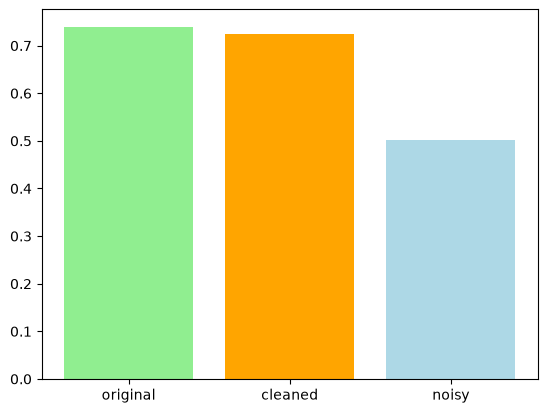

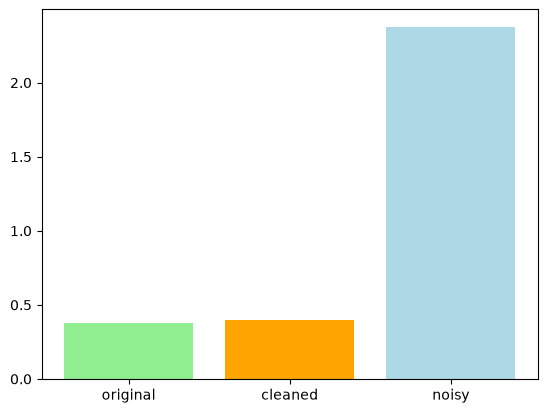

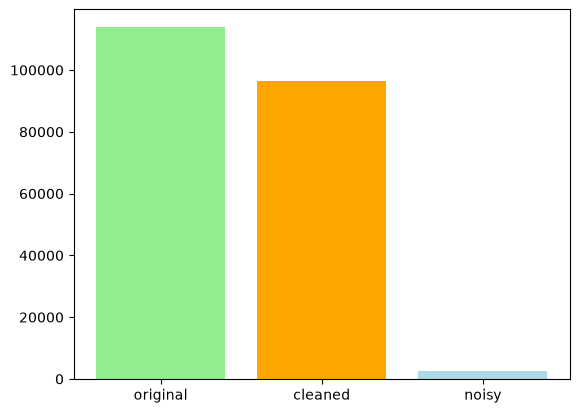

In [32]:
try:
    plt.bar(['original', 'cleaned', 'noisy'], [o_ss, c_ss, n_ss], color=['lightgreen', 'orange', 'lightblue'])
    plt.show()

    plt.bar(['original', 'cleaned', 'noisy'], [o_dbi, c_dbi, n_dbi], color=['lightgreen', 'orange', 'lightblue'])
    plt.show()

    plt.bar(['original', 'cleaned', 'noisy'], [o_chi, c_chi, n_chi], color=['lightgreen', 'orange', 'lightblue'])
    plt.show()
except:
    plt.bar(['cleaned', 'noisy'], [c_ss, n_ss], color=['orange', 'lightblue'])
    plt.show()

    plt.bar(['cleaned', 'noisy'], [c_dbi, n_dbi], color=['orange', 'lightblue'])
    plt.show()

    plt.bar(['cleaned', 'noisy'], [c_chi, n_chi], color=['orange', 'lightblue'])
    plt.show()